In [ ]:
%pip -q install kagglehub

In [ ]:
import re
import shutil
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

SEED = 42
N_FOLDS = 5
EPOCHS = 35
PATIENCE = 9
TARGET = 0.90
BATCH_SIZE = 24
IMAGE_SIZE = 128
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
OUTPUT = Path("/content/ckplus_results")
OUTPUT.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE)

Device: cuda


In [ ]:
archive = Path("/content/ckplus.zip")
if archive.is_file():
    root = Path("/content/ckplus_data")
    root.mkdir(exist_ok=True)
    shutil.unpack_archive(str(archive), str(root))
else:
    try:
        root = Path(kagglehub.dataset_download("shawon10/ckplus"))
    except Exception as error:
        raise RuntimeError("Upload the CK+48 dataset ZIP as /content/ckplus.zip and rerun this cell.") from error

classes = ["anger", "contempt", "disgust", "fear", "happy", "sad", "surprise"]
class_ids = {name: index for index, name in enumerate(classes)}
aliases = {"angry": "anger", "happiness": "happy", "sadness": "sad",
           "fearful": "fear", "surprised": "surprise", "disgusted": "disgust",
           "contemptuous": "contempt"}
frame_pattern = re.compile(r"(?:^|[^A-Za-z0-9])(S[0-9]+)[_-]([0-9]+)[_-]([0-9]+)(?![0-9])", re.IGNORECASE)
image_suffixes = {".png", ".jpg", ".jpeg", ".bmp"}
peak_frames = {}
unreadable_names = []

for path in sorted(root.rglob("*")):
    if not path.is_file() or path.suffix.lower() not in image_suffixes:
        continue
    name = path.parent.name.lower()
    expression = aliases.get(name, name)
    if expression not in class_ids:
        continue

    match = frame_pattern.search(path.stem)
    if match is None:
        unreadable_names.append(path.name)
        continue

    subject, sequence, frame = match.groups()
    subject = f"S{int(subject[1:]):03d}"
    sequence = int(sequence)
    frame = int(frame)
    key = (subject, sequence)
    old = peak_frames.get(key)
    if old is not None and old["expression"] != expression:
        raise ValueError(f"Conflicting class labels for sequence {key}.")
    if old is None or frame > old["frame"]:
        peak_frames[key] = {
            "path": path, "subject": subject, "sequence": sequence,
            "frame": frame, "expression": expression, "label": class_ids[expression],
        }

if not peak_frames:
    raise ValueError("No labeled CK+ sequences found. Check the archive and keep original filenames.")
if unreadable_names:
    print(f"Ignored {len(unreadable_names)} filenames without CK+ identifiers.")
samples = pd.DataFrame(peak_frames.values()).sort_values(
    ["subject", "sequence"]
).reset_index(drop=True)
if set(samples["expression"]) != set(classes):
    raise ValueError("Expected labeled CK+48 images for all seven classes.")

y = samples["label"].to_numpy()
groups = samples["subject"].to_numpy()
print(f"{len(samples)} peak frames from {samples['subject'].nunique()} subjects.")
display(samples.groupby("expression")["subject"].agg(["size", "nunique"]))

100%|██████████| 3.63M/3.63M [00:00<00:00, 152MB/s]

Extracting files...


327 peak frames from 118 subjects.


,size,nunique
expression,,
anger,45,45
contempt,18,18
disgust,59,59
fear,25,25
happy,69,69
sad,28,28
surprise,83,83


100%|██████████| 3.63M/3.63M [00:00<00:00, 73.6MB/s]

Extracting files...


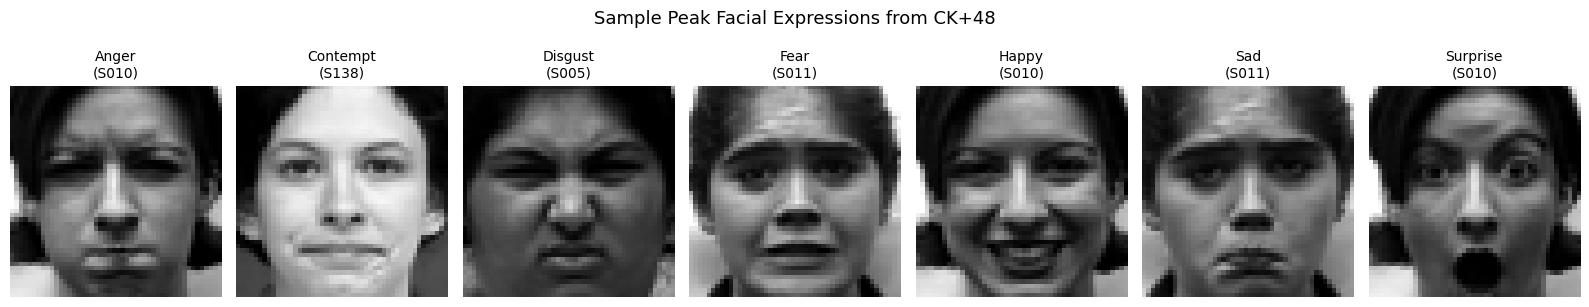

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import re
import kagglehub
from pathlib import Path
from PIL import Image

try:
    classes
    samples
except NameError:
    # Dynamically locate/download the dataset cache directory
    try:
        root = Path(kagglehub.dataset_download("shawon10/ckplus"))
    except Exception:
        root = Path("/content/ckplus_data")

    classes = ["anger", "contempt", "disgust", "fear", "happy", "sad", "surprise"]
    class_ids = {name: index for index, name in enumerate(classes)}
    aliases = {"angry": "anger", "happiness": "happy", "sadness": "sad",
               "fearful": "fear", "surprised": "surprise", "disgusted": "disgust",
               "contemptuous": "contempt"}
    frame_pattern = re.compile(r"(?:^|[^A-Za-z0-9])(S[0-9]+)[_-]([0-9]+)[_-]([0-9]+)(?![0-9])", re.IGNORECASE)
    image_suffixes = {".png", ".jpg", ".jpeg", ".bmp"}
    peak_frames = {}

    if root.exists():
        for path in sorted(root.rglob("*")):
            if not path.is_file() or path.suffix.lower() not in image_suffixes:
                continue
            name = path.parent.name.lower()
            expression = aliases.get(name, name)
            if expression not in class_ids:
                continue

            match = frame_pattern.search(path.stem)
            if match is None:
                continue

            subject, sequence, frame = match.groups()
            subject = f"S{int(subject[1:]):03d}"
            sequence = int(sequence)
            frame = int(frame)
            key = (subject, sequence)
            old = peak_frames.get(key)
            if old is None or frame > old["frame"]:
                peak_frames[key] = {
                    "path": path, "subject": subject, "sequence": sequence,
                    "frame": frame, "expression": expression, "label": class_ids[expression],
                }
        samples = pd.DataFrame(peak_frames.values()).sort_values(["subject", "sequence"]).reset_index(drop=True)
    else:
        raise RuntimeError("The dataset variables are missing and could not be recovered. Please run cell JEDCMl6iS3-- first.")

OUTPUT = Path("/content/ckplus_results")
OUTPUT.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, len(classes), figsize=(16, 3))
for idx, cls in enumerate(classes):
    sample_row = samples[samples["expression"] == cls].iloc[0]
    img = Image.open(sample_row["path"]).convert("RGB")
    axes[idx].imshow(img)
    axes[idx].set_title(f"{cls.capitalize()}\n({sample_row['subject']})", fontsize=10)
    axes[idx].axis("off")
plt.suptitle("Sample Peak Facial Expressions from CK+48", fontsize=13, y=1.05)
plt.tight_layout()
plt.savefig(OUTPUT / "sample_expressions.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
all_labels = list(range(len(classes)))
indices = np.arange(len(samples))
outer = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = []

for fold, (pool, test) in enumerate(outer.split(indices, y, groups), 1):
    inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + fold)
    candidates = []
    for train_local, val_local in inner.split(pool, y[pool], groups[pool]):
        train, val = pool[train_local], pool[val_local]
        if len(np.unique(y[train])) == len(classes):
            candidates.append((train, val))
    if not candidates:
        raise ValueError(f"Fold {fold} has no training split that includes all seven classes.")

    train, val = max(
        candidates, key=lambda split: (len(np.unique(y[split[1]])), -abs(len(split[1]) - len(pool) / 4))
    )
    assert not set(groups[train]).intersection(groups[val])
    assert not set(groups[train]).intersection(groups[test])
    assert not set(groups[val]).intersection(groups[test])
    folds.append((train, val, test))
    print(f"Fold {fold}: {len(train)} train, {len(val)} validation, {len(test)} test images")

assert sorted(np.concatenate([test for _, _, test in folds]).tolist()) == indices.tolist()

resize = transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))
normalize = transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
train_transform = transforms.Compose([
    resize,
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(8, translate=(0.06, 0.06), scale=(0.92, 1.08),
                            interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ColorJitter(brightness=0.18, contrast=0.18),
    transforms.ToTensor(),
    normalize,
])
eval_transform = transforms.Compose([resize, transforms.ToTensor(), normalize])

class Faces(Dataset):
    def __init__(self, rows, transform):
        self.rows = rows[["path", "label"]].to_records(index=False)
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        path, label = self.rows[index]
        with Image.open(path) as image:
            image = self.transform(image.convert("RGB"))
        return image, int(label)

def make_loader(index, training=False, seed=SEED):
    transform = train_transform if training else eval_transform
    return DataLoader(
        Faces(samples.iloc[index], transform),
        batch_size=BATCH_SIZE,
        shuffle=training,
        pin_memory=USE_AMP,
        num_workers=2,
        generator=torch.Generator().manual_seed(seed),
    )

Fold 1: 191 train, 67 validation, 69 test images
Fold 2: 194 train, 61 validation, 72 test images
Fold 3: 198 train, 66 validation, 63 test images
Fold 4: 202 train, 67 validation, 58 test images
Fold 5: 199 train, 63 validation, 65 test images


In [ ]:
class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()
        layers = []
        for previous, channels in [(3, 32), (32, 64), (64, 128), (128, 192)]:
            layers.extend([
                nn.Conv2d(previous, channels, 3, padding=1, bias=False),
                nn.BatchNorm2d(channels), nn.ReLU(inplace=True),
                nn.Conv2d(channels, channels, 3, padding=1, bias=False),
                nn.BatchNorm2d(channels), nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            ])
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((3, 3)), nn.Flatten(),
            nn.Linear(192 * 3 * 3, 192), nn.ReLU(), nn.Dropout(0.35),
            nn.Linear(192, len(classes)),
        )

    def forward(self, images):
        return self.classifier(self.features(images))

def build_model(name, pretrained=True):
    if name == "Custom CNN":
        return CustomCNN()
    if name == "ResNet-18":
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        model = models.resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, len(classes))
        return model
    if name == "MobileNetV3-Small":
        weights = models.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None
        model = models.mobilenet_v3_small(weights=weights)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(classes))
        return model
    raise ValueError(f"Unknown model: {name}")

settings = {
    "Custom CNN": ("custom_cnn", 0.001),
    "ResNet-18": ("resnet18", 0.0003),
    "MobileNetV3-Small": ("mobilenet_v3_small", 0.0003),
}

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC


@torch.inference_mode()
def extract_features(encoder, image_indices):
    batches = []
    encoder.eval()

    for images, _ in make_loader(image_indices):
        images = images.to(DEVICE)
        original = encoder(images).flatten(1)
        flipped = encoder(images.flip(-1)).flatten(1)
        features = F.normalize((original + flipped) / 2, dim=1)
        batches.append(features.cpu().numpy())

    return np.concatenate(batches, axis=0)


def select_classifier(candidates, train_x, train_y, val_x, val_y):
    best_classifier = None
    best_score = (-1.0, -1.0)

    for classifier in candidates:
        classifier.fit(train_x, train_y)
        predicted = classifier.predict(val_x)
        score = (
            accuracy_score(val_y, predicted),
            f1_score(
                val_y, predicted,
                labels=all_labels,
                average="macro",
                zero_division=0,
            ),
        )

        if score > best_score:
            best_score = score
            best_classifier = classifier

    return best_classifier


baseline = predictions.loc[predictions["Model"].eq("ResNet-18")].copy()
baseline["Method"] = "ResNet-18 original head"
results = baseline[["Method", "Image index", "Actual", "Predicted"]].to_dict("records")

for fold, (train_idx, val_idx, test_idx) in enumerate(folds, 1):
    print(f"Fold {fold}/{len(folds)}", flush=True)

    resnet = load_fold_model("ResNet-18", "resnet18", fold).eval()
    encoder = nn.Sequential(*list(resnet.children())[:-1]).eval()

    train_x = extract_features(encoder, train_idx)
    val_x = extract_features(encoder, val_idx)
    test_x = extract_features(encoder, test_idx)

    methods = {
        "ResNet-18 features + RBF-SVM": [
            SVC(C=c, kernel="rbf", gamma="scale", class_weight=weight)
            for c in (0.1, 1, 10, 100)
            for weight in (None, "balanced")
        ],
        "ResNet-18 features + logistic regression": [
            LogisticRegression(C=c, class_weight=weight, max_iter=2000)
            for c in (0.1, 1, 10, 100)
            for weight in (None, "balanced")
        ],
    }

    for name, candidates in methods.items():
        classifier = select_classifier(
            candidates, train_x, y[train_idx], val_x, y[val_idx]
        )
        guessed = classifier.predict(test_x)

        for index, label in zip(test_idx, guessed):
            results.append({
                "Method": name,
                "Image index": int(index),
                "Actual": int(y[index]),
                "Predicted": int(label),
            })

    del encoder, resnet

method_predictions = pd.DataFrame(results)
summary = []

for name, rows in method_predictions.groupby("Method", sort=False):
    assert sorted(rows["Image index"].tolist()) == indices.tolist()
    score = accuracy_score(rows["Actual"], rows["Predicted"])

    summary.append({
        "Method": name,
        "Held-out accuracy (%)": 100 * score,
        "90% target met": score >= 0.90,
    })

method_comparison = pd.DataFrame(summary)
display(method_comparison.round(2))
method_comparison.to_csv(
    OUTPUT / "three_classifier_comparison.csv", index=False
)

Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5


,Method,Held-out accuracy (%),90% target met
0,ResNet-18 original head,93.27,True
1,ResNet-18 features + RBF-SVM,95.11,True
2,ResNet-18 features + logistic regression,93.58,True


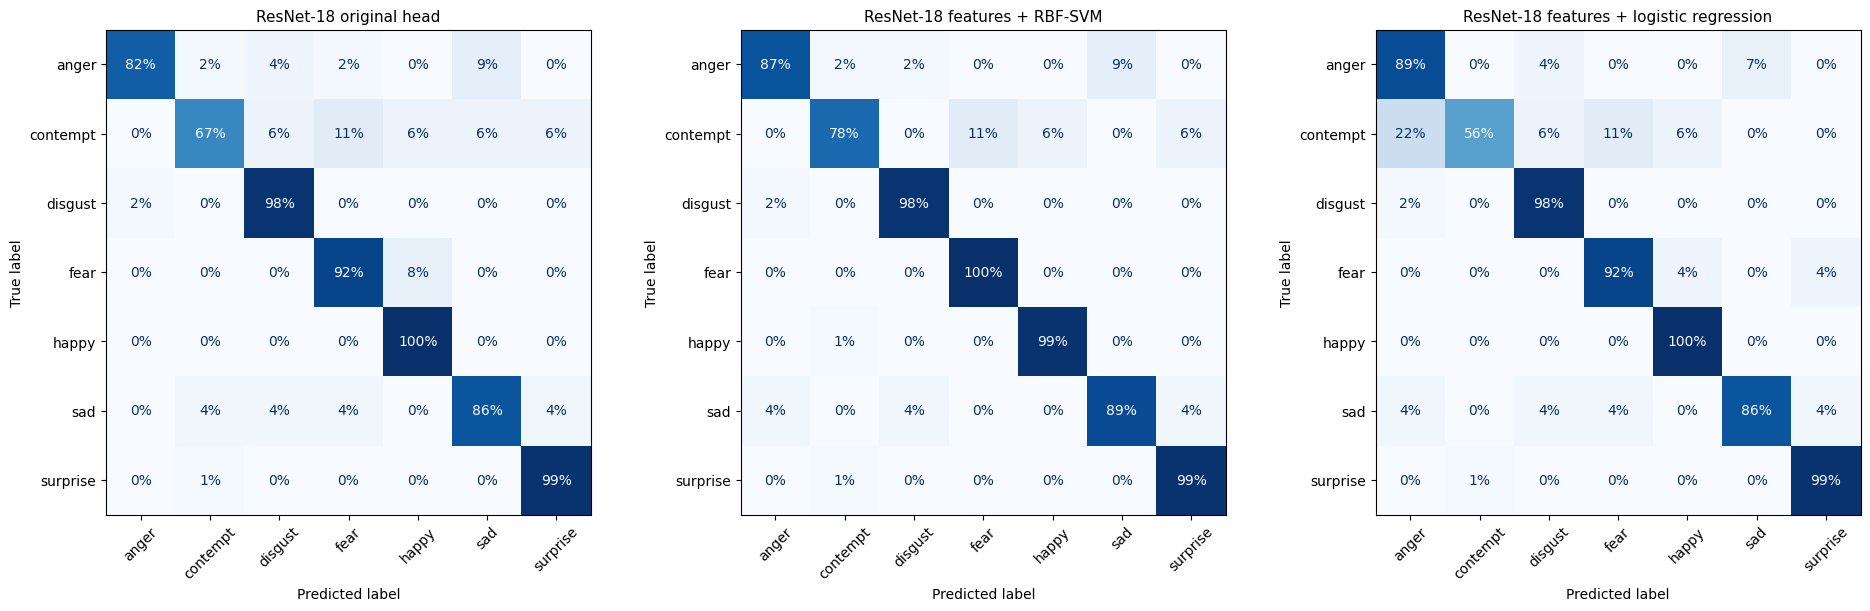

,Method,Held-out accuracy (%),90% target met,Points below 90
0,ResNet-18 original head,93.27,True,0.0
1,ResNet-18 features + RBF-SVM,95.11,True,0.0
2,ResNet-18 features + logistic regression,93.58,True,0.0


All three classifier methods reached 90% on these CK+ folds.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6), layout="constrained")

for ax, (name, rows) in zip(
    axes, method_predictions.groupby("Method", sort=False)
):
    ConfusionMatrixDisplay.from_predictions(
        rows["Actual"],
        rows["Predicted"],
        labels=all_labels,
        display_labels=classes,
        normalize="true",
        values_format=".0%",
        cmap="Blues",
        colorbar=False,
        xticks_rotation=45,
        ax=ax,
    )
    ax.set_title(name, fontsize=11)

figure_path = OUTPUT / "three_classifier_confusion_matrices.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

summary = method_comparison.copy()
summary["Points below 90"] = (
    90 - summary["Held-out accuracy (%)"]
).clip(lower=0)

display(summary.round(2))

below_target = summary.loc[~summary["90% target met"], "Method"].tolist()
if below_target:
    print("Methods below 90%:", ", ".join(below_target))
else:
    print("All three classifier methods reached 90% on these CK+ folds.")

Ground Truth Expression: SURPRISE (Subject: S010)


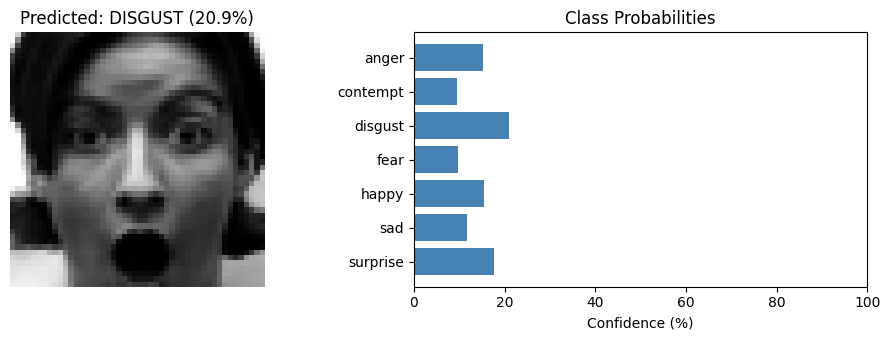

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold
from torchvision import models, transforms

# Fallback to recreate configs and device if not in memory
try:
    DEVICE
except NameError:
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

try:
    eval_transform
except NameError:
    IMAGE_SIZE = 128
    resize = transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))
    normalize = transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
    eval_transform = transforms.Compose([resize, transforms.ToTensor(), normalize])

# Fallback to recreate folds and other dependencies if they are not in memory
try:
    folds
except NameError:
    SEED = 42
    N_FOLDS = 5
    y = samples["label"].to_numpy()
    groups = samples["subject"].to_numpy()
    indices = np.arange(len(samples))
    outer = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    folds = []
    for fold, (pool, test) in enumerate(outer.split(indices, y, groups), 1):
        inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + fold)
        candidates = []
        for train_local, val_local in inner.split(pool, y[pool], groups[pool]):
            train, val = pool[train_local], pool[val_local]
            if len(np.unique(y[train])) == len(classes):
                candidates.append((train, val))
        train, val = max(
            candidates, key=lambda split: (len(np.unique(y[split[1]])), -abs(len(split[1]) - len(pool) / 4))
        )
        folds.append((train, val, test))

try:
    build_model
except NameError:
    class CustomCNN(nn.Module):
        def __init__(self):
            super().__init__()
            layers = []
            for previous, channels in [(3, 32), (32, 64), (64, 128), (128, 192)]:
                layers.extend([
                    nn.Conv2d(previous, channels, 3, padding=1, bias=False),
                    nn.BatchNorm2d(channels), nn.ReLU(inplace=True),
                    nn.Conv2d(channels, channels, 3, padding=1, bias=False),
                    nn.BatchNorm2d(channels), nn.ReLU(inplace=True),
                    nn.MaxPool2d(2),
                ])
            self.features = nn.Sequential(*layers)
            self.classifier = nn.Sequential(
                nn.AdaptiveAvgPool2d((3, 3)), nn.Flatten(),
                nn.Linear(192 * 3 * 3, 192), nn.ReLU(), nn.Dropout(0.35),
                nn.Linear(192, len(classes)),
            )

        def forward(self, images):
            return self.classifier(self.features(images))

    def build_model(name, pretrained=True):
        if name == "Custom CNN":
            return CustomCNN()
        if name == "ResNet-18":
            weights = models.ResNet18_Weights.DEFAULT if pretrained else None
            model = models.resnet18(weights=weights)
            model.fc = nn.Linear(model.fc.in_features, len(classes))
            return model
        if name == "MobileNetV3-Small":
            weights = models.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None
            model = models.mobilenet_v3_small(weights=weights)
            model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(classes))
            return model
        raise ValueError(f"Unknown model: {name}")

try:
    load_fold_model
except NameError:
    def load_fold_model(model_name, filename_prefix, fold):
        model = build_model(model_name, pretrained=False)
        model_path = Path(f"/content/ckplus_results/{filename_prefix}_fold{fold}.pt")
        if model_path.exists():
            model.load_state_dict(torch.load(model_path, map_location=DEVICE))
        else:
            print(f"Warning: {model_path} not found. Running inference with randomly initialized weights.")
        return model.to(DEVICE)

@torch.inference_mode()
def predict_single_image(image_path, fold=1):
    model = load_fold_model("ResNet-18", "resnet18", fold).eval()
    with Image.open(image_path) as img:
        rgb_img = img.convert("RGB")
        tensor = eval_transform(rgb_img).unsqueeze(0).to(DEVICE)

    logits = (model(tensor) + model(tensor.flip(-1))) / 2.0
    probs = F.softmax(logits, dim=1).squeeze(0).cpu().numpy()
    pred_idx = int(probs.argmax())

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
    ax1.imshow(rgb_img)
    ax1.set_title(f"Predicted: {classes[pred_idx].upper()} ({probs[pred_idx]*100:.1f}%)")
    ax1.axis("off")

    ax2.barh(classes, probs * 100, color="steelblue")
    ax2.set_xlim(0, 100)
    ax2.set_xlabel("Confidence (%)")
    ax2.set_title("Class Probabilities")
    ax2.invert_yaxis()
    plt.tight_layout()
    plt.show()

# Test inference on a sample from Fold 1's held-out test set
sample_test_idx = folds[0][2][0]
sample_row = samples.iloc[sample_test_idx]
print(f"Ground Truth Expression: {sample_row['expression'].upper()} (Subject: {sample_row['subject']})")
predict_single_image(sample_row["path"], fold=1)